In [1]:
from utils import *
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import seaborn as sns
from matplotlib.lines import Line2D
import warnings
warnings.filterwarnings("ignore")

In [2]:
data_dict={}
data_dict["ctc_ral3-tstr"]="CTC n2560 RAL3.2"
data_dict["ctc_gal9-tstr"]="CTC n2560 GAL9"
data_dict["ctc_ral3-fstr"]="CTC_RAL3p2"
data_dict["ctc_gal9-fstr"]="CTC_GAL9"
sims=["ctc_gal9","ctc_ral3"]

In [3]:
for sim in sims:
    data_dict[sim+"-aew_tracks"]=xr.open_dataset(f"~/QTrack/{data_dict[sim+"-fstr"]}_AEW_tracks_post_processed.nc")
    data_dict[sim+"-winds"]=xr.open_dataset(f"/gws/ssde/j25b/lmcs/bmaybee/aew_work/DY2_{data_dict[sim+"-fstr"]}_uv700_1deg-32Next.nc")
    data_dict[sim+"-density_ref"]=xr.open_dataset(f"/gws/ssde/j25b/lmcs/bmaybee/aew_work/DY2_{data_dict[sim+"-fstr"]}_EAtl_density_0p5deg2.nc").mean(dim=["longitude","latitude"]).density
    for p in [850,600,200]:
        data_dict[sim+"-lossett_p%03d"%p]=xr.open_dataset(f"/gws/ssde/j25b/lmcs/bmaybee/aew_work/DY2_{data_dict[sim+"-fstr"]}_losset_n640_p{p}.nc")

In [4]:
root=f"/gws/ssde/j25b/kscale/DATA/outdir_20160801T0000Z/DMn1280GAL9/channel_n2560_RAL3p2/"
dystr="20160801T0000Z"

In [5]:
hues=sns.color_palette("colorblind")

In [6]:
def load_file(ffile,var_name):
    return xr.open_dataset(root+ffile)[var_name].sel(latitude=slice(0,30),longitude=slice(-45,40))

In [7]:
def get_panel(ax,var,tstamp,plev=None,lscale=None,lon_slice=[-30,10],nrow=20,ncol=1):
    tstr_suff=""
    date_str="%04d%02d%02d"%(tstamp.year,tstamp.month,tstamp.day)
    bt=load_file(f"single_olwr/{date_str}_{dystr}_channel_olwr_hourly.nc","toa_outgoing_longwave_flux").sel(longitude=slice(lon_slice[0],lon_slice[-1]))
    bt=tb_from_olr(bt)
    precip=load_file(f"precip/{date_str}_{dystr}_channel_precip_hourly.nc","precipitation_rate").sel(longitude=slice(lon_slice[0],lon_slice[-1]))
    
    if var=="TCW":
        date=tstamp-pd.Timedelta(3,"h")
        date_str="%04d%02d%02d"%(date.year,date.month,date.day)
        tcw=load_file(f"single_qtot/{date_str}_{dystr}_channel_qtot_3hourly.nc","total_column_q")
        Cb=(tcw.sel(time=tstamp)-tcw_clim.sel(hour=tstamp.hour)).sel(longitude=slice(lon_slice[0],lon_slice[-1])
                    ).plot.contourf(ax=ax,cmap="RdBu",levels=np.arange(-25,30,5),extend="both",add_colorbar=False)
        tstr_suff,lab=": TCW anomaly","TCW anomaly (mm)"
        
    elif var=="PV":
        ds=(pv_field.sel(time=tstamp)-pv_clim.sel(hour=tstamp.hour)).sel(longitude=slice(lon_slice[0],lon_slice[-1]))
        Cb=(1e6*ds).plot.contourf(ax=ax,cmap="RdBu",levels=np.arange(-1.5,1.6,0.3),extend="both",add_colorbar=False)
        tstr_suff,lab=": %shPa PV anomaly"%plev,f"{plev}hPa PV anomaly (PVU)"
    
    elif "lossett_p" in var:
        vmax=0.0005
        data=data_dict[sim+"-density_ref"].sel(pressure=plev)*data_dict[sim+f"-lossett_p{plev}"].sel(time=tstamp,length_scale=lscale*1000,pressure=plev,longitude=slice(lon_slice[0],lon_slice[-1])).Dl_u
        Cb=data.plot.contourf(ax=ax,cmap="RdBu_r",vmax=vmax,levels=11,extend="both",add_colorbar=False)
        tstr_suff,lab=f": {plev}hPa {2*lscale}km ISET",r"%shPa $\bar\rho_{\rm ref}\mathcal{D}_{%s}$ (kg m$^{-1}$ s$^{-3}$)" % (plev,2*lscale)
    
    elif var=="lossett_grad":
        if plev<400:
            vmax=0.001
        else:
            vmax=0.0005
        Cb=(data_dict[sim+"-lossett"].sel(time=tstamp,length_scale=550*1000,pressure=plev) - data_dict[sim+"-lossett"].sel(time=tstamp,length_scale=220*1000,pressure=plev)
                       ).sel(longitude=slice(lon_slice[0],lon_slice[-1])).Dl_u.T.plot.contourf(ax=ax,cmap="BrBG",vmax=vmax,levels=11,extend="both",add_colorbar=False)
        tstr_suff=r": %shPa 440$\rightarrow$1100km ISET gradient"%plev,r"%shPa $\Delta\mathcal{D}_{L}$ (m$^2$ s$^{-3}$)" % (plev)
        
    data_dict[sim+"-winds"].sel(time=tstamp,longitude=slice(lon_slice[0],lon_slice[-1])
                               ).plot.streamplot(ax=ax,x="longitude",y="latitude",u="u",v="v",color="Grey")
    #Cu=data_dict[sim+"-winds"].u.sel(time=tstamp,longitude=slice(lon_slice[0],lon_slice[-1])
    #                                ).plot.contour(ax=ax,linewidths=2.5,colors="Orange",linestyles="--",levels=[-10])
    #ax.clabel(Cu)
    bt.sel(time=tstamp,method="nearest").plot.contour(ax=ax,colors="hotpink",alpha=1,linestyles="--",levels=[223])
    precip.sel(time=tstamp,method="nearest").plot.contour(ax=ax,colors="gold",alpha=0.7,levels=[4])
    aew_tracks=data_dict[sim+"-aew_tracks"].sel(longitude=slice(lon_slice[0],lon_slice[-1]))
    aew_lons,aew_lats=aew_tracks.sel(time=tstamp)["AEW_lon_smooth"].values,aew_tracks.sel(time=tstamp)["AEW_lat_smooth"].values
    ax.scatter(aew_lons,aew_lats,s=75,marker="x",color="k",zorder=99)
    ax.coastlines()
    ax.set_xlim(lon_slice)
    ax.set_ylim([3,20])
    ax.set_title(tstamp,fontsize=14)

    gl = ax.gridlines(crs = ccrs.PlateCarree(),draw_labels=True,linestyle="None")
    gl.ylines = False
    gl.xlines = False
    gl.top_labels = False
    gl.right_labels = False
    gl.bottom_labels = False

    return ax, Cb

In [8]:
def get_aew_panel(ax1,tstamp,lon_slice=[-30,10]):
    aew_tracks=data_dict["ctc_ral3-aew_tracks"]
    aew_tracks=aew_tracks.where((aew_tracks.AEW_lon_smooth>lon_slice[0]) & (aew_tracks.AEW_lon_smooth<lon_slice[-1]+5),drop=True)
    for s in aew_tracks.sel(time=tstamp).AEW_strength.dropna(dim="system").system.values:
        track=aew_tracks.sel(system=s,time=slice(None,tstamp))
        ax1.plot(track.AEW_lon_smooth,10e4*track.AEW_strength,color=hues[int(s)%10])
    ax1.set_title("")
    ax1.set_ylim([0,3])
    ax1.yaxis.tick_right()
    ax1.yaxis.set_label_position("right")
    ax1.set_xticks(np.arange(-30,10,10))
    ax1.set_xticklabels([r"30$^\circ$W",r"20$^\circ$W",r"10$^\circ$W",r"0$^\circ$E"])
    ax1.set_yticks([0,1,2])
    ax1.set_ylabel(r"CV$_{\rm AEW}$"+"\n(10$^{-5}$ s$^{-1}$)")
    return ax1

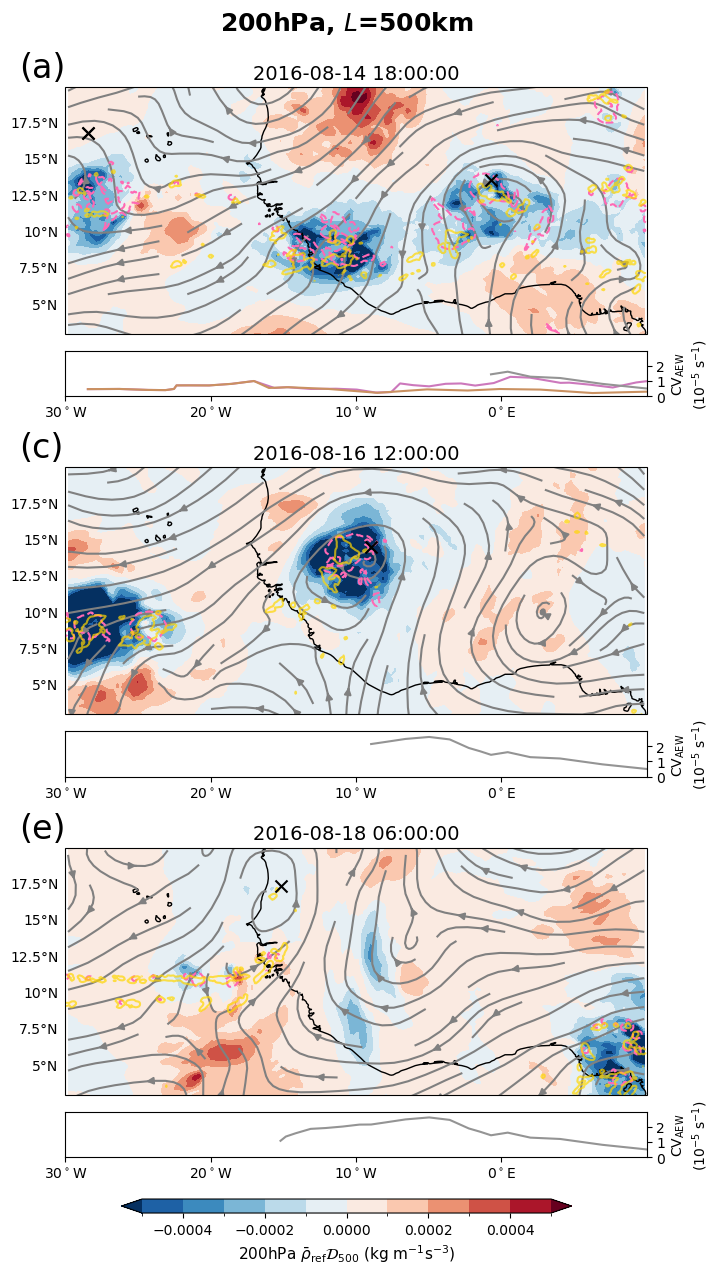

In [9]:
fig=plt.figure(figsize=(7.5,14))#,subplot_kw=dict(projection=ccrs.PlateCarree()))

plev,lscale=200,250
tstamp=pd.Timestamp("2016-08-14 18:00")
ax_t1=fig.add_subplot(20,1,(1,5),projection=ccrs.PlateCarree())
ax_t1, Cb=get_panel(ax_t1,f"lossett_p{plev}",tstamp,plev=plev,lscale=lscale)
ax1_t1=fig.add_subplot(20,1,6,sharex=ax_t1)
ax1_t1=get_aew_panel(ax1_t1,tstamp)
ax_t1.text(-0.08,1.04,"(a)",fontsize=24,transform=ax_t1.transAxes)

tstamp=pd.Timestamp("2016-08-16 12:00")
ax_t2=fig.add_subplot(20,1,(8,12),projection=ccrs.PlateCarree())
ax_t2,Cb=get_panel(ax_t2,f"lossett_p{plev}",tstamp,plev=plev,lscale=lscale)
ax1_t2=fig.add_subplot(20,1,13,sharex=ax_t2)
ax1_t2=get_aew_panel(ax1_t2,tstamp)
ax_t2.text(-0.08,1.04,"(c)",fontsize=24,transform=ax_t2.transAxes)

tstamp=pd.Timestamp("2016-08-18 06:00")
ax_t3=fig.add_subplot(20,1,(15,19),projection=ccrs.PlateCarree())
ax_t3, Cb=get_panel(ax_t3,f"lossett_p{plev}",tstamp,plev=plev,lscale=lscale)
ax1_t3=fig.add_subplot(20,1,20,sharex=ax_t3)
ax1_t3=get_aew_panel(ax1_t3,tstamp)
ax_t3.text(-0.08,1.04,"(e)",fontsize=24,transform=ax_t3.transAxes)

fig.suptitle(f"200hPa, $L$={2*lscale}km",y=0.93,fontsize=18,weight="bold")
cax = fig.add_axes([0.2,0.07,0.6,0.01])
clb=fig.colorbar(Cb, cax = cax, orientation = "horizontal").set_label(r"%shPa $\bar\rho_{\rm ref}\mathcal{D}_{%s}$ (kg m$^{-1}$s$^{-3}$)"%(plev,2*lscale),fontsize=11)

fig.savefig("Figures/Case_study_system7_200hPa_L=550km.png",dpi=200,bbox_inches="tight",facecolor="white")

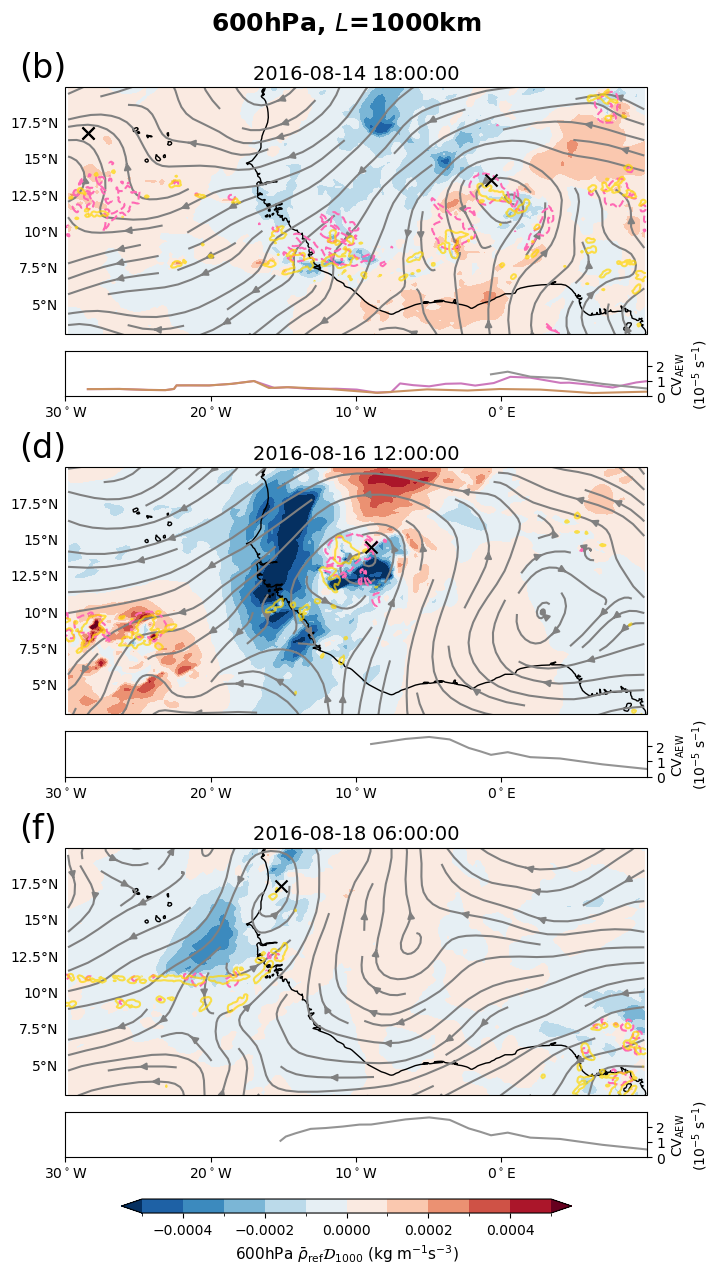

In [10]:
fig=plt.figure(figsize=(7.5,14))#,subplot_kw=dict(projection=ccrs.PlateCarree()))

plev,lscale=600,500
tstamp=pd.Timestamp("2016-08-14 18:00")
ax_t1=fig.add_subplot(20,1,(1,5),projection=ccrs.PlateCarree())
ax_t1, Cb=get_panel(ax_t1,f"lossett_p{plev}",tstamp,plev=plev,lscale=lscale)
ax1_t1=fig.add_subplot(20,1,6,sharex=ax_t1)
ax1_t1=get_aew_panel(ax1_t1,tstamp)
ax_t1.text(-0.08,1.04,"(b)",fontsize=24,transform=ax_t1.transAxes)

tstamp=pd.Timestamp("2016-08-16 12:00")
ax_t2=fig.add_subplot(20,1,(8,12),projection=ccrs.PlateCarree())
ax_t2,Cb=get_panel(ax_t2,f"lossett_p{plev}",tstamp,plev=plev,lscale=lscale)
ax1_t2=fig.add_subplot(20,1,13,sharex=ax_t2)
ax1_t2=get_aew_panel(ax1_t2,tstamp)
ax_t2.text(-0.08,1.04,"(d)",fontsize=24,transform=ax_t2.transAxes)

tstamp=pd.Timestamp("2016-08-18 06:00")
ax_t3=fig.add_subplot(20,1,(15,19),projection=ccrs.PlateCarree())
ax_t3, Cb=get_panel(ax_t3,f"lossett_p{plev}",tstamp,plev=plev,lscale=lscale)
ax1_t3=fig.add_subplot(20,1,20,sharex=ax_t3)
ax1_t3=get_aew_panel(ax1_t3,tstamp)
ax_t3.text(-0.08,1.04,"(f)",fontsize=24,transform=ax_t3.transAxes)

fig.suptitle("%shPa, $L$=%skm"%(plev,2*lscale),y=0.93,fontsize=18,weight="bold")
cax = fig.add_axes([0.2,0.07,0.6,0.01])
clb=fig.colorbar(Cb, cax = cax, orientation = "horizontal").set_label(r"%shPa $\bar\rho_{\rm ref}\mathcal{D}_{%s}$ (kg m$^{-1}$s$^{-3}$)"%(plev,2*lscale),fontsize=11)


fig.savefig("Figures/Case_study_system7_600hPa_L=1100km.png",dpi=200,bbox_inches="tight",facecolor="white")

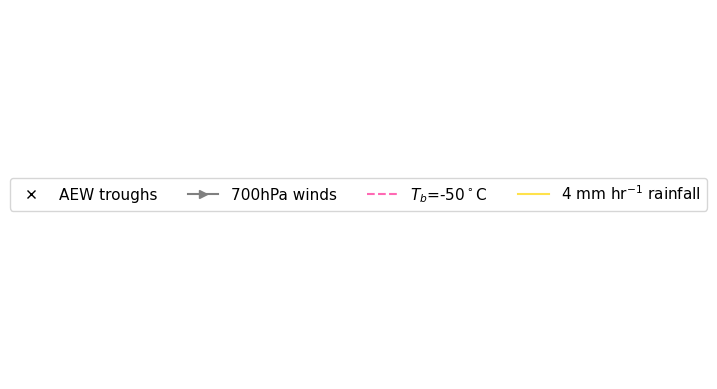

In [11]:
fig,ax=plt.subplots()
ax.axis("off")
fig.legend(handles=[Line2D([],[], color="k", marker="x", linestyle="None", label="AEW troughs"),
                   Line2D([],[], color="grey", marker=">", label="700hPa winds"),
                   #Line2D([],[], color="sandybrown", marker="", lw=2, ls="--", linestyle=None, label="$u_{700}$=-10 ms$^{-1}$"),
                   Line2D([],[], color="hotpink", marker="", ls="--", label=r"$T_b$=-50$^\circ$C"),
                   Line2D([],[], color="gold", marker="", alpha=0.7, label=r"4 mm hr$^{-1}$ rainfall")],
           fontsize='11', ncols=4, loc="center")
fig.savefig(f"Figures/Case_study_legend.png",dpi=200,bbox_inches="tight",facecolor="white")